# Bài 4 (Trang 26): Phân lớp dữ liệu Red Wine Quality
**Sinh viên:** Trần Nhất Long - 6451071042

In [1]:
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn import tree
from sklearn.naive_bayes import GaussianNB
from sklearn import metrics

print("Trần Nhất Long - 6451071042")
data = pd.read_csv("winequality-red.csv")
print("Kích thước dữ liệu:", data.shape)
print("Số giá trị bị thiếu:", data.isnull().sum().sum())
data.info()
data.head()

Trần Nhất Long - 6451071042
Kích thước dữ liệu: (1599, 12)
Số giá trị bị thiếu: 0
<class 'pandas.DataFrame'>
RangeIndex: 1599 entries, 0 to 1598
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1599 non-null   float64
 1   volatile acidity      1599 non-null   float64
 2   citric acid           1599 non-null   float64
 3   residual sugar        1599 non-null   float64
 4   chlorides             1599 non-null   float64
 5   free sulfur dioxide   1599 non-null   float64
 6   total sulfur dioxide  1599 non-null   float64
 7   density               1599 non-null   float64
 8   pH                    1599 non-null   float64
 9   sulphates             1599 non-null   float64
 10  alcohol               1599 non-null   float64
 11  quality               1599 non-null   int64  
dtypes: float64(11), int64(1)
memory usage: 150.0 KB


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


## Câu 3: Khảo sát độ tương đồng giữa các cột bằng công thức Pearson

Trần Nhất Long - 6451071042


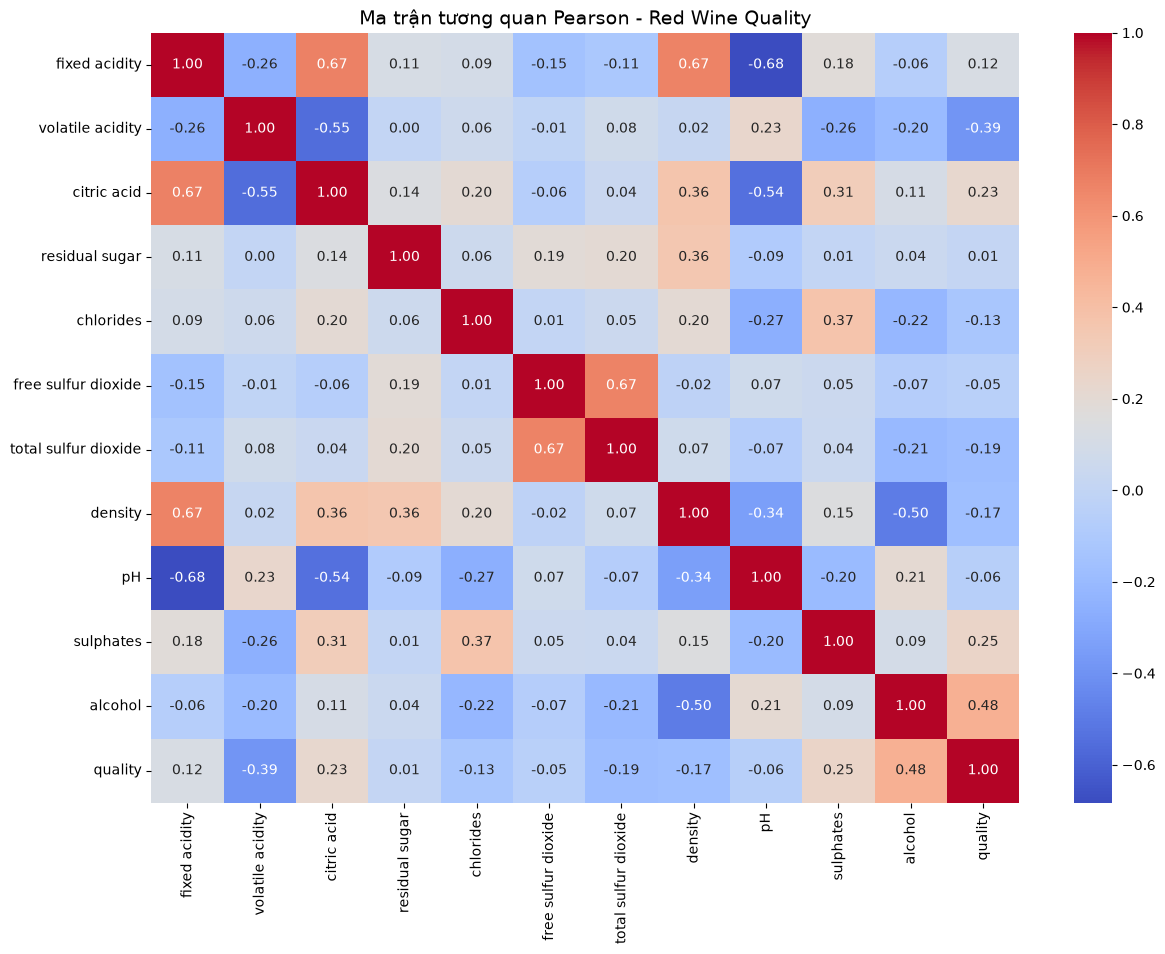

Nhận xét: Các cặp thuộc tính có độ tương quan cao nhất là fixed acidity & pH (-0.68), fixed acidity & citric acid (0.67), fixed acidity & density (0.67), free sulfur dioxide & total sulfur dioxide (0.67). Các giá trị đều dưới ngưỡng tương đồng rất cao (0.8), nên giữ lại toàn bộ các cột thuộc tính.


In [2]:
print("Trần Nhất Long - 6451071042")
plt.figure(figsize=(14, 10))
corr_matrix = data.corr(method="pearson", numeric_only=True)
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Ma trận tương quan Pearson - Red Wine Quality", fontsize=14)
plt.show()

print("Nhận xét: Các cặp thuộc tính có độ tương quan cao nhất là fixed acidity & pH (-0.68), fixed acidity & citric acid (0.67), fixed acidity & density (0.67), free sulfur dioxide & total sulfur dioxide (0.67). Các giá trị đều dưới ngưỡng tương đồng rất cao (0.8), nên giữ lại toàn bộ các cột thuộc tính.")

## Câu 4: Tách dữ liệu thành thuộc tính đầu vào (`features`) và thuộc tính quyết định (`quality`)

In [3]:
print("Trần Nhất Long - 6451071042")
features = data.drop("quality", axis=1)
labels = data["quality"]
print("Kích thước features:", features.shape)
print("Kích thước labels:", labels.shape)
print("Phân bố nhãn quality:")
print(labels.value_counts().sort_index())

Trần Nhất Long - 6451071042
Kích thước features: (1599, 11)
Kích thước labels: (1599,)
Phân bố nhãn quality:
quality
3     10
4     53
5    681
6    638
7    199
8     18
Name: count, dtype: int64


## Câu 5: Kiểm tra và chuyển đổi các cột không phải dạng số về one-hot vector (nếu có)

In [4]:
print("Trần Nhất Long - 6451071042")
non_numeric_cols = features.select_dtypes(exclude=["int64", "float64"]).columns
print("Các cột không phải dạng số:", list(non_numeric_cols))
if len(non_numeric_cols) > 0:
    features_onehot = pd.get_dummies(features, columns=non_numeric_cols)
else:
    features_onehot = features.copy()
    print("Tất cả 11 thuộc tính đều đã ở dạng số, không cần chuyển đổi one-hot.")
features_onehot.head()

Trần Nhất Long - 6451071042
Các cột không phải dạng số: []
Tất cả 11 thuộc tính đều đã ở dạng số, không cần chuyển đổi one-hot.


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4


## Câu 6: Chia dữ liệu đầu vào thành 70% huấn luyện và 30% kiểm thử

In [5]:
print("Trần Nhất Long - 6451071042")
X_train, X_test, y_train, y_test = train_test_split(
    features_onehot, labels, test_size=0.3, random_state=42
)
print("X_train:", X_train.shape, "| y_train:", y_train.shape)
print("X_test:", X_test.shape, "| y_test:", y_test.shape)

Trần Nhất Long - 6451071042
X_train: (1119, 11) | y_train: (1119,)
X_test: (480, 11) | y_test: (480,)


## Câu 7: Xây dựng cây ID3 (`criterion='entropy'`), ma trận nhầm lẫn và biểu diễn cây

Trần Nhất Long - 6451071042
Accuracy (ID3): 0.5833333333333334
Report (ID3):
               precision    recall  f1-score   support

           3       0.00      0.00      0.00         1
           4       0.08      0.12      0.10        17
           5       0.70      0.66      0.68       195
           6       0.60      0.60      0.60       200
           7       0.43      0.46      0.44        61
           8       0.25      0.17      0.20         6

    accuracy                           0.58       480
   macro avg       0.34      0.33      0.34       480
weighted avg       0.59      0.58      0.59       480



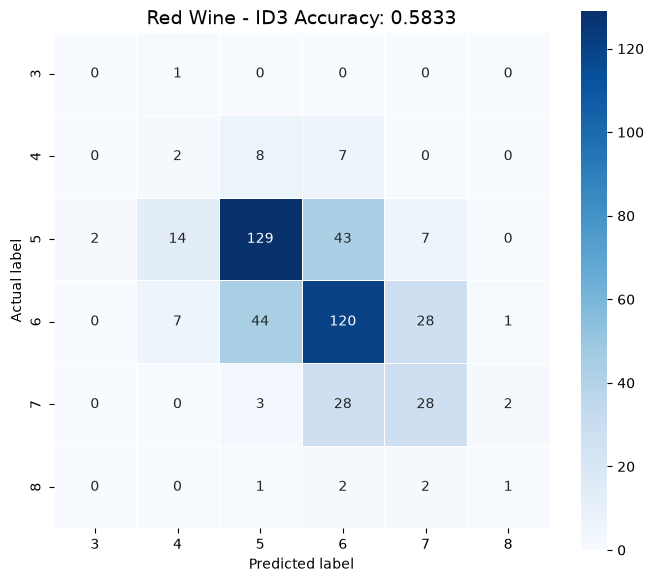

Độ sâu cây ID3: 18, số nút lá: 273


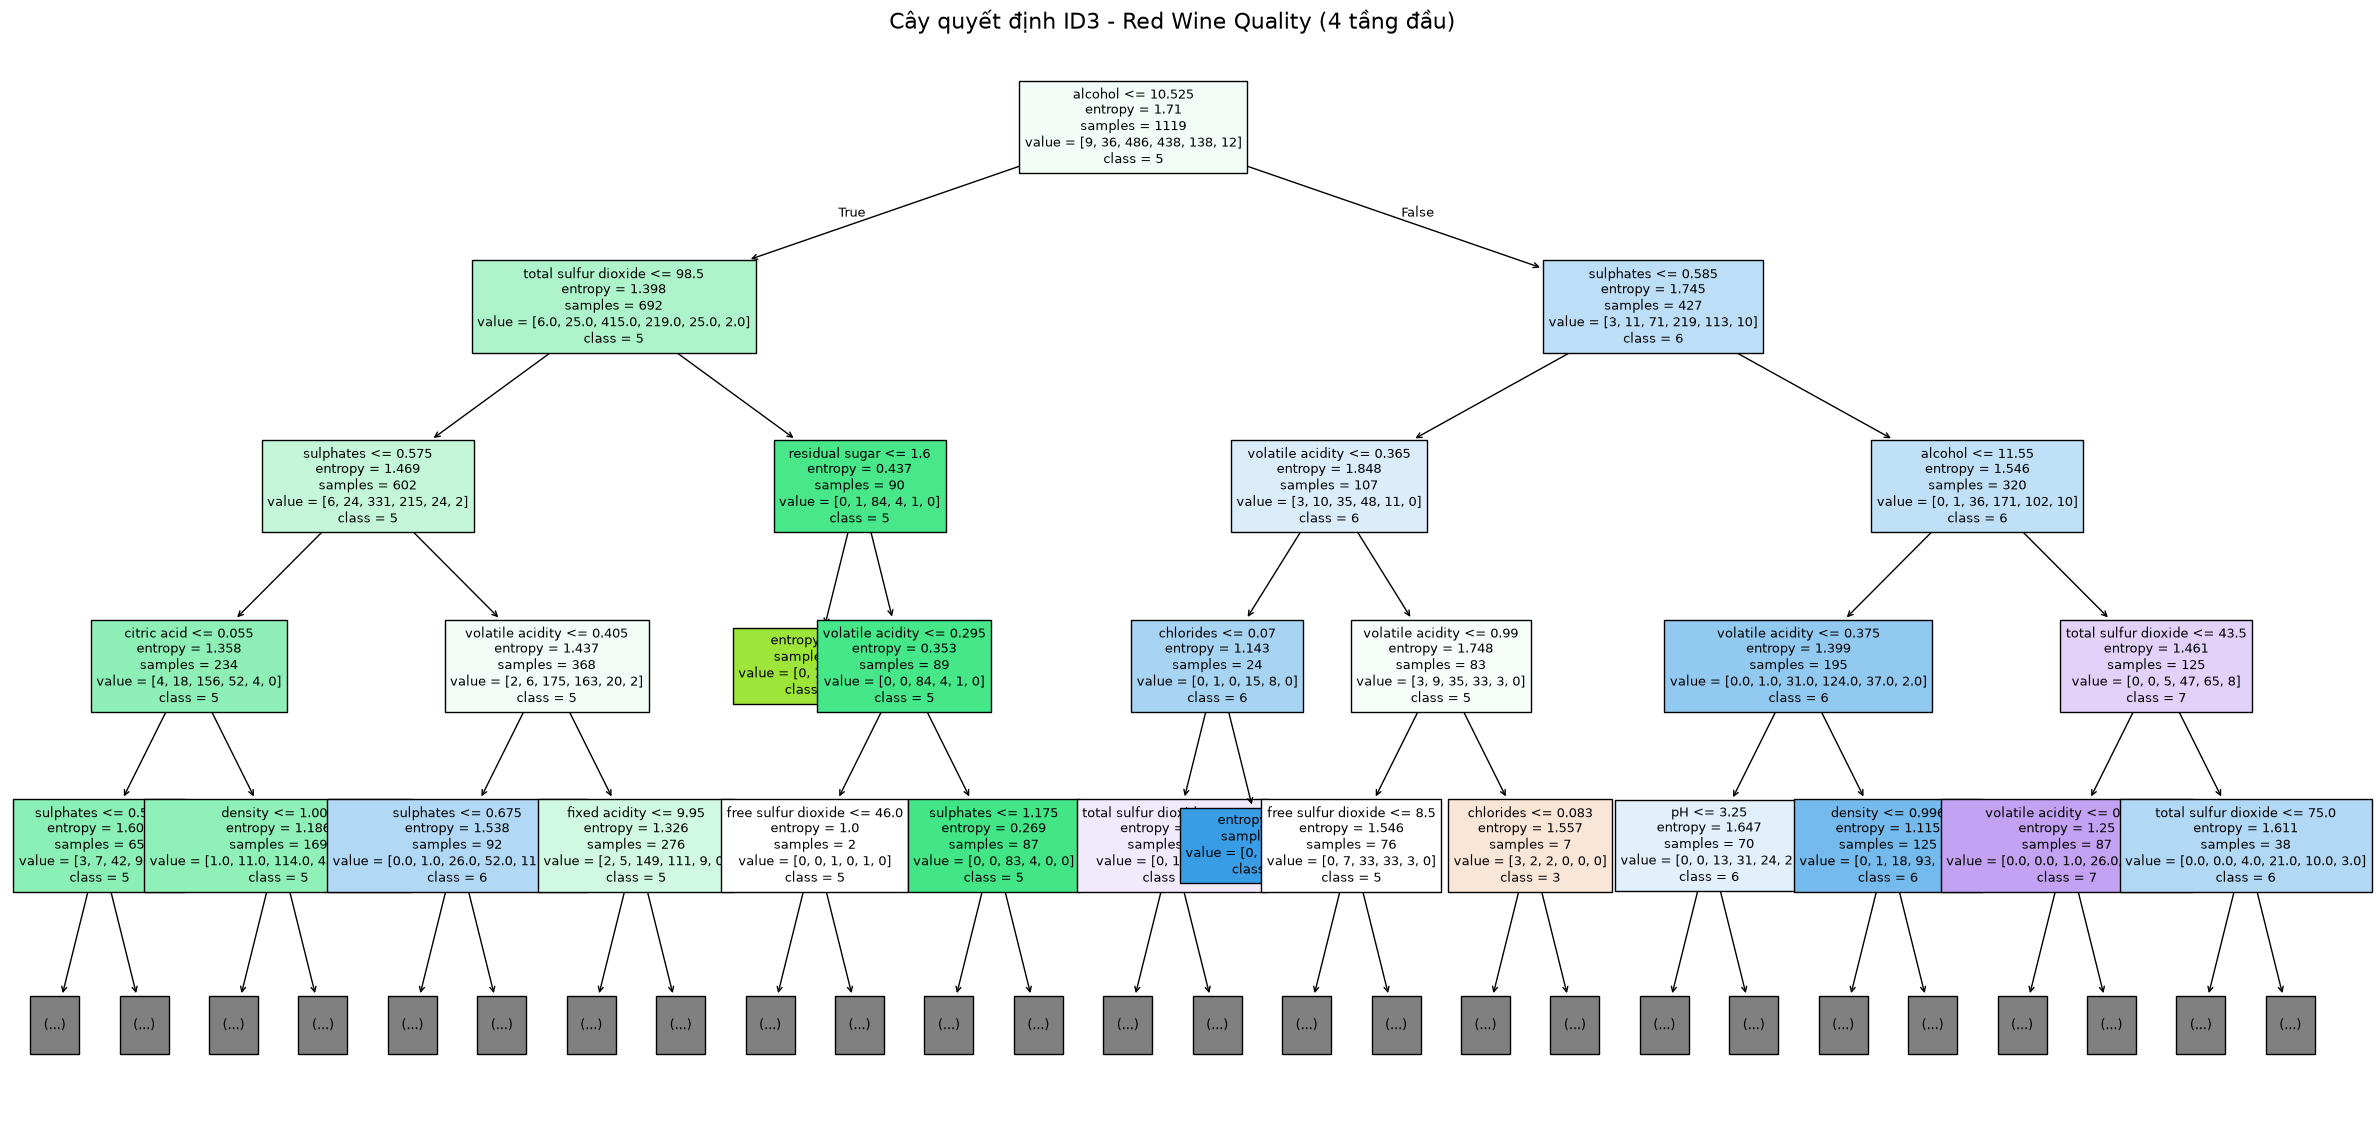

In [6]:
print("Trần Nhất Long - 6451071042")
clf_id3 = tree.DecisionTreeClassifier(criterion="entropy", random_state=0)
clf_id3.fit(X_train, y_train)
id3_pred = clf_id3.predict(X_test)

id3_score = metrics.accuracy_score(y_test, id3_pred)
class_labels = sorted(labels.unique())
print("Accuracy (ID3):", id3_score)
print("Report (ID3):\n", metrics.classification_report(y_test, id3_pred, zero_division=0))

id3_cm = metrics.confusion_matrix(y_test, id3_pred, labels=class_labels)
plt.figure(figsize=(8, 7))
sns.heatmap(id3_cm, annot=True, fmt="d", linewidths=0.5, square=True, cmap="Blues",
            xticklabels=class_labels, yticklabels=class_labels)
plt.ylabel("Actual label")
plt.xlabel("Predicted label")
plt.title(f"Red Wine - ID3 Accuracy: {id3_score:.4f}", size=14)
plt.show()

print(f"Độ sâu cây ID3: {clf_id3.get_depth()}, số nút lá: {clf_id3.get_n_leaves()}")
fig, ax = plt.subplots(figsize=(30, 14))
tree.plot_tree(
    clf_id3,
    feature_names=list(features_onehot.columns),
    class_names=[str(c) for c in clf_id3.classes_],
    filled=True,
    fontsize=9,
    max_depth=4,
)
plt.title("Cây quyết định ID3 - Red Wine Quality (4 tầng đầu)", fontsize=16)
plt.savefig("decision_tree_id3_wine.png", dpi=100, bbox_inches="tight")
plt.show()

## Câu 8: Xây dựng cây CART (`criterion='gini'`), ma trận nhầm lẫn và biểu diễn cây

Trần Nhất Long - 6451071042
Accuracy (CART): 0.5625
Report (CART):
               precision    recall  f1-score   support

           3       0.00      0.00      0.00         1
           4       0.07      0.06      0.06        17
           5       0.64      0.62      0.63       195
           6       0.57      0.58      0.57       200
           7       0.45      0.49      0.47        61
           8       0.33      0.33      0.33         6

    accuracy                           0.56       480
   macro avg       0.34      0.35      0.35       480
weighted avg       0.56      0.56      0.56       480



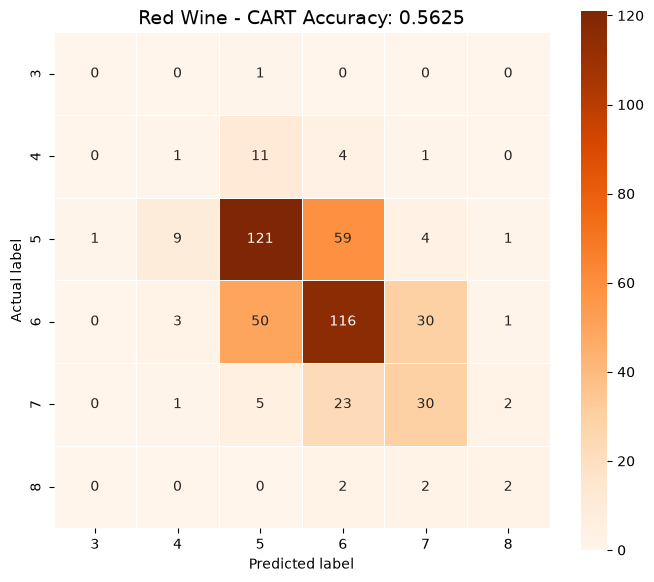

Độ sâu cây CART: 19, số nút lá: 287


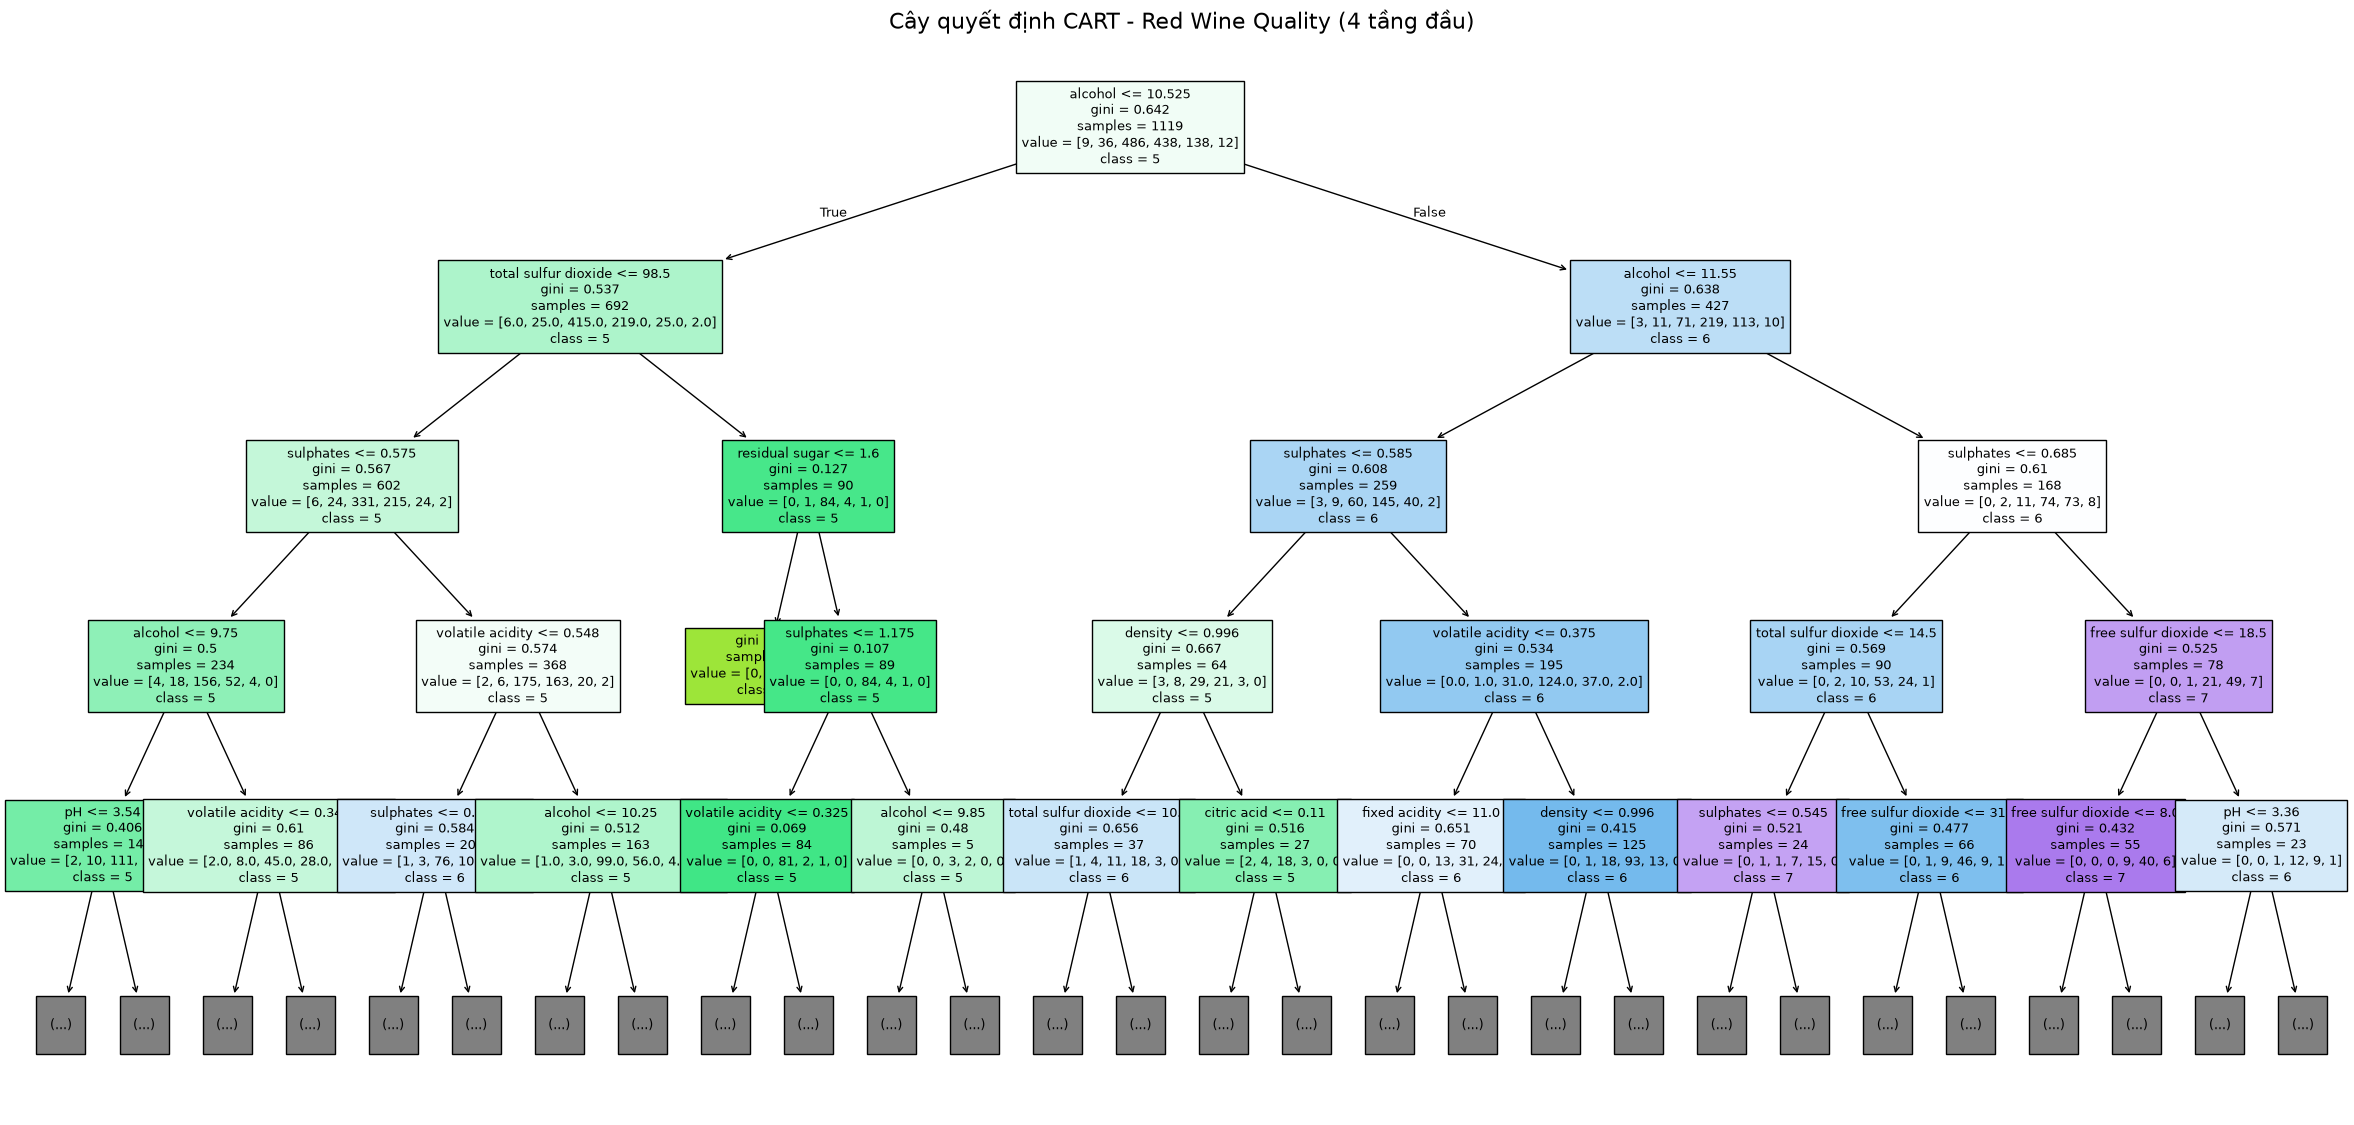

In [7]:
print("Trần Nhất Long - 6451071042")
clf_cart = tree.DecisionTreeClassifier(criterion="gini", random_state=0)
clf_cart.fit(X_train, y_train)
cart_pred = clf_cart.predict(X_test)

cart_score = metrics.accuracy_score(y_test, cart_pred)
print("Accuracy (CART):", cart_score)
print("Report (CART):\n", metrics.classification_report(y_test, cart_pred, zero_division=0))

cart_cm = metrics.confusion_matrix(y_test, cart_pred, labels=class_labels)
plt.figure(figsize=(8, 7))
sns.heatmap(cart_cm, annot=True, fmt="d", linewidths=0.5, square=True, cmap="Oranges",
            xticklabels=class_labels, yticklabels=class_labels)
plt.ylabel("Actual label")
plt.xlabel("Predicted label")
plt.title(f"Red Wine - CART Accuracy: {cart_score:.4f}", size=14)
plt.show()

print(f"Độ sâu cây CART: {clf_cart.get_depth()}, số nút lá: {clf_cart.get_n_leaves()}")
fig, ax = plt.subplots(figsize=(30, 14))
tree.plot_tree(
    clf_cart,
    feature_names=list(features_onehot.columns),
    class_names=[str(c) for c in clf_cart.classes_],
    filled=True,
    fontsize=9,
    max_depth=4,
)
plt.title("Cây quyết định CART - Red Wine Quality (4 tầng đầu)", fontsize=16)
plt.savefig("decision_tree_cart_wine.png", dpi=100, bbox_inches="tight")
plt.show()

## Câu 9: Xây dựng mô hình Naïve Bayes (`GaussianNB`) và kiểm tra kết quả

Trần Nhất Long - 6451071042
Accuracy (Naïve Bayes): 0.5416666666666666
Report (Naïve Bayes):
               precision    recall  f1-score   support

           3       0.00      0.00      0.00         1
           4       0.12      0.12      0.12        17
           5       0.68      0.62      0.65       195
           6       0.52      0.54      0.53       200
           7       0.40      0.49      0.44        61
           8       0.00      0.00      0.00         6

    accuracy                           0.54       480
   macro avg       0.29      0.29      0.29       480
weighted avg       0.55      0.54      0.54       480



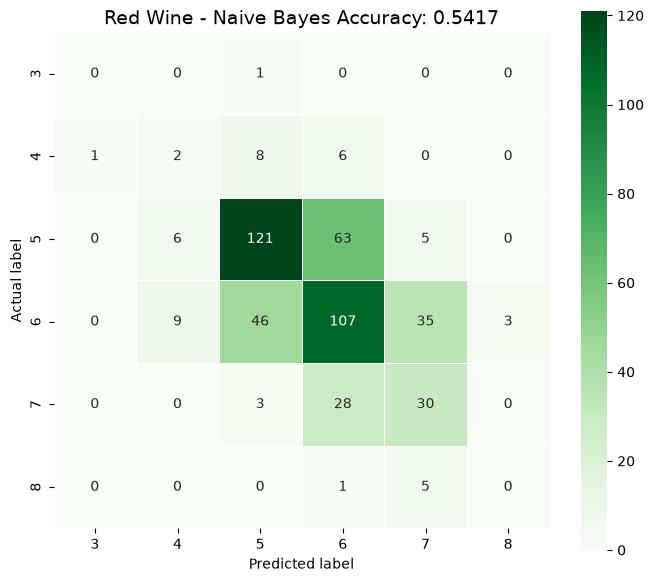

In [8]:
print("Trần Nhất Long - 6451071042")
gnb = GaussianNB()
bayes_pred = gnb.fit(X_train, y_train).predict(X_test)

bayes_score = metrics.accuracy_score(y_test, bayes_pred)
print("Accuracy (Naïve Bayes):", bayes_score)
print("Report (Naïve Bayes):\n", metrics.classification_report(y_test, bayes_pred, zero_division=0))

bayes_cm = metrics.confusion_matrix(y_test, bayes_pred, labels=class_labels)
plt.figure(figsize=(8, 7))
sns.heatmap(bayes_cm, annot=True, fmt="d", linewidths=0.5, square=True, cmap="Greens",
            xticklabels=class_labels, yticklabels=class_labels)
plt.ylabel("Actual label")
plt.xlabel("Predicted label")
plt.title(f"Red Wine - Naive Bayes Accuracy: {bayes_score:.4f}", size=14)
plt.show()

## Câu 10: So sánh kết quả của các mô hình

Trần Nhất Long - 6451071042
                 Mô hình  Accuracy  Precision (Weighted)  Recall (Weighted)  F1-score (Weighted)
           ID3 (Entropy)  0.583333              0.594097           0.583333             0.588259
             CART (Gini)  0.562500              0.561997           0.562500             0.561986
Naïve Bayes (GaussianNB)  0.541667              0.547096           0.541667             0.543265


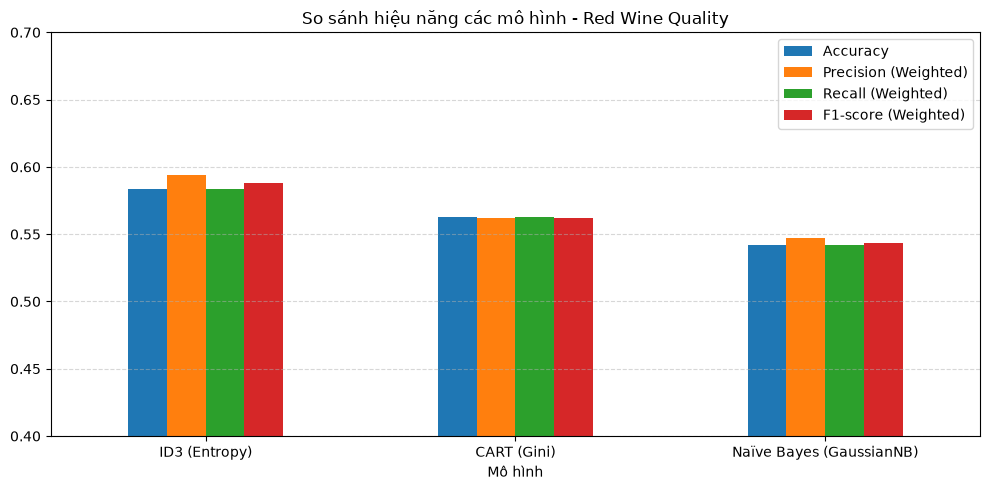


Nhận xét:
- Cây quyết định (ID3 và CART) đạt độ chính xác cao hơn rõ rệt so với Naïve Bayes trên tập Red Wine Quality.
- Các thuộc tính hóa lý của rượu vang có sự tương quan đáng kể với nhau (không hoàn toàn độc lập có điều kiện), nên giả định độc lập của Naïve Bayes làm giảm độ chính xác.


In [9]:
print("Trần Nhất Long - 6451071042")
results = []
for name, pred in [("ID3 (Entropy)", id3_pred), ("CART (Gini)", cart_pred), ("Naïve Bayes (GaussianNB)", bayes_pred)]:
    results.append({
        "Mô hình": name,
        "Accuracy": metrics.accuracy_score(y_test, pred),
        "Precision (Weighted)": metrics.precision_score(y_test, pred, average="weighted", zero_division=0),
        "Recall (Weighted)": metrics.recall_score(y_test, pred, average="weighted", zero_division=0),
        "F1-score (Weighted)": metrics.f1_score(y_test, pred, average="weighted", zero_division=0),
    })

df_compare = pd.DataFrame(results)
print(df_compare.to_string(index=False))

df_compare.set_index("Mô hình").plot(kind="bar", figsize=(10, 5), ylim=(0.4, 0.7))
plt.title("So sánh hiệu năng các mô hình - Red Wine Quality")
plt.xticks(rotation=0)
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

print("\nNhận xét:")
print("- Cây quyết định (ID3 và CART) đạt độ chính xác cao hơn rõ rệt so với Naïve Bayes trên tập Red Wine Quality.")
print("- Các thuộc tính hóa lý của rượu vang có sự tương quan đáng kể với nhau (không hoàn toàn độc lập có điều kiện), nên giả định độc lập của Naïve Bayes làm giảm độ chính xác.")